In [288]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

In [289]:
def gradient_step(w, y_true, X, lr):
    n = X.shape[0]
    e = X @ w - y_true
    grad = (2 / n) * ((X.T) @ e)
    return w - lr * grad

def mse(y_pred, y_true):
    return np.sum((y_pred - y_true) ** 2) / y_pred.shape[0]

In [290]:
features = ["w0", "temperature2", "calibration2", "hour_cos", "hour_sin", "control_ab"]
train = pd.read_csv("train.csv")

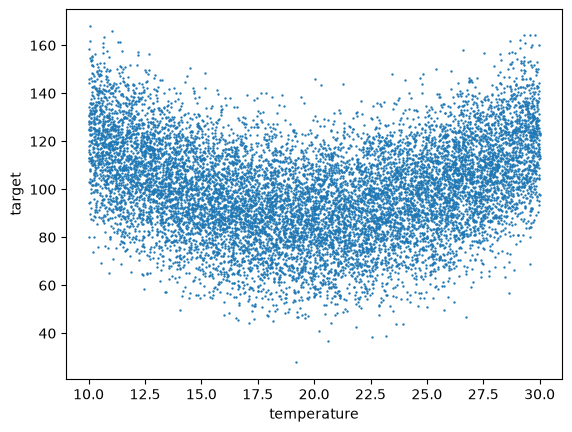

In [291]:
plt.scatter(train["temperature"], train["target"], s=0.5)
plt.xlabel("temperature")
plt.ylabel("target")
plt.show()

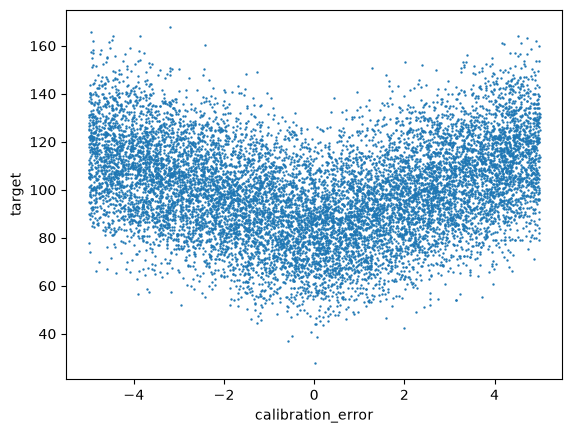

In [292]:
plt.scatter((train["calibration_error"]), train["target"], s=0.5)
plt.xlabel("calibration_error")
plt.ylabel("target")
plt.show()

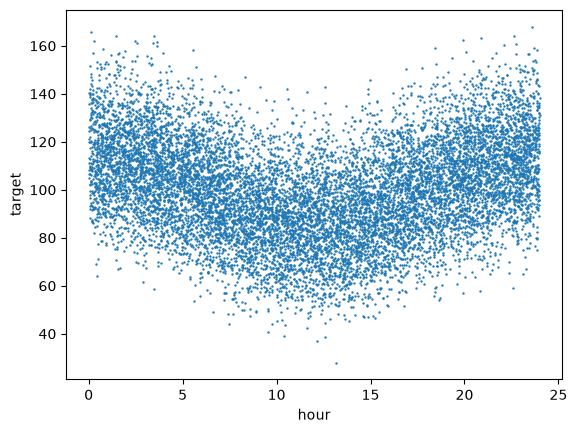

In [293]:
plt.scatter(train["hour"], train["target"], s=0.5)
plt.xlabel("hour")
plt.ylabel("target")
plt.show()

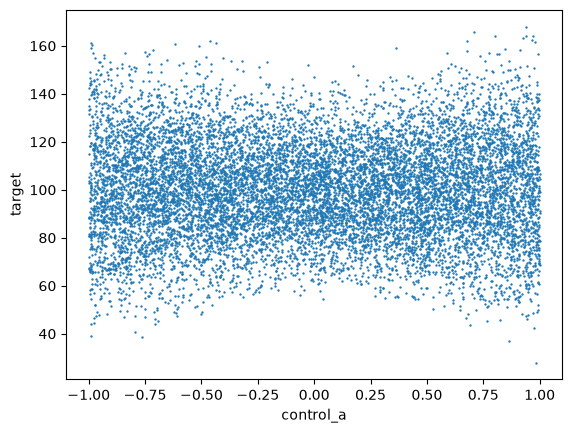

In [294]:
plt.scatter(train["control_a"], train["target"], s=0.5)
plt.xlabel("control_a")
plt.ylabel("target")
plt.show()

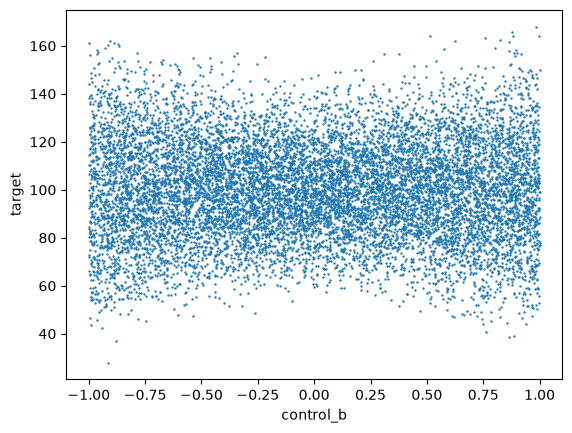

In [295]:
plt.scatter(train["control_b"], train["target"], s=0.5)
plt.xlabel("control_b")
plt.ylabel("target")
plt.show()

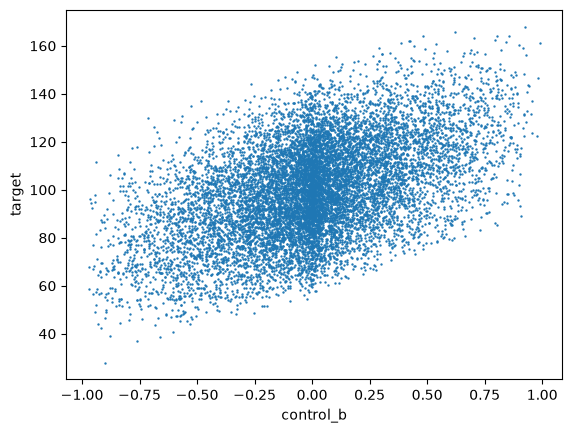

In [296]:
plt.scatter(train["control_b"] * train["control_a"], train["target"], s=0.5)
plt.xlabel("control_b")
plt.ylabel("target")
plt.show()

In [297]:
def format(table):
    table.insert(0, column="w0", value=np.ones(len(table)))
    table["temperature2"] = (20 - table["temperature"]) ** 2
    table["calibration2"] = abs(table["calibration_error"])
    table["hour_cos"] = np.cos(2 * np.pi * table["hour"] / 24)
    table["hour_sin"] = np.sin(2 * np.pi * table["hour"] / 24)
    table["control_ab"] = table["control_a"] * table["control_b"]
    X = np.array(table[features])
    y_true = np.array(table["target"])
    X_std = X.std(axis = 0)
    X_mean = X.mean(axis = 0)
    X_mean[0] = 0
    X_std[0] = 1
    X_norm = (X - X_mean) / X_std
    y_true_norm = (y_true - (y_true.mean())) / (y_true.std())
    return X, y_true, X_norm, y_true_norm, y_true.mean(), y_true.std(), X_mean, X_std
def format2(table):
    table.insert(0, column="w0", value=np.ones(len(table)))
    table["temperature2"] = (20 - table["temperature"]) ** 2
    table["calibration2"] = abs(table["calibration_error"])
    table["hour_cos"] = np.cos(2 * np.pi * table["hour"] / 24)
    table["hour_sin"] = np.sin(2 * np.pi * table["hour"] / 24)
    table["control_ab"] = table["control_a"] * table["control_b"]
    return table

[2.24620322e-16 4.97221147e-01 4.94929959e-01 1.47571798e-03
 4.96489486e-01]


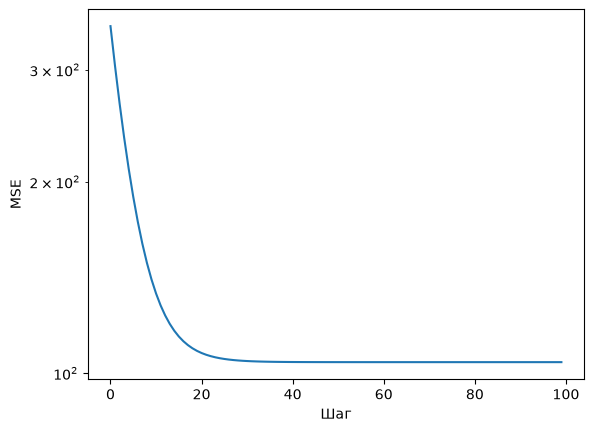

351.2889778524443
104.06782218226003


In [298]:
X, y_true, X_norm, y_true_norm, y_mean, y_std, X_mean, X_std = format(train)
w = np.zeros(6)
history = []
for i in range(100):
    w = gradient_step(w, y_true_norm, X_norm, 0.05)
    prediction = X_norm @ w
    history.append(mse(prediction * y_std + y_mean, y_true))
print(w)
plt.plot(history)
plt.yscale("log")
plt.xlabel("Шаг")
plt.ylabel("MSE")
plt.show()
print(history[0])
print(history[-1])

In [299]:
valid = format2(pd.read_csv("validation.csv"))
X_valid = np.array(valid[features])
X_valid_norm = (X_valid - X_mean) / X_std
prediction_valid = (X_valid_norm @ w) * y_std + y_mean
y_valid = valid["target"]
submission_v = pd.read_csv("baseline_validation.csv")
submission_v["target"] = prediction_valid
submission_v.to_csv("submission_valid.csv", index=False)

In [300]:
test = format2(pd.read_csv("test.csv"))
X_test = np.array(test[features])
X_test_norm = (X_test - X_mean) / X_std
prediction_test = (X_test_norm @ w) * y_std + y_mean
submission = pd.read_csv("baseline_submission.csv")
submission["target"] = prediction_test
submission.to_csv("submissionE.csv", index=False)